# Several condition keys, a cell-type hierarchy and new cell types

Real atlases rarely have a single batch variable and a single, complete annotation. This
tutorial uses scPoli's features for that situation:

- **several condition keys.** Here `study` and the sequencing `technology`, each with its own
  learned embedding;
- **a hierarchy of labels.** Fine `cell_type` and coarse `cell_type_coarse` share one
  prototype space, and both are predicted;
- **imperfect labels.** Some cells are annotated `"unknown"`, and only part of the reference is
  used as labeled;
- **new cell types.** A type absent from the reference is found in the query and added as a
  new prototype.

The data is the pancreas dataset of the first tutorial.

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import seaborn as sns
from sklearn.metrics import accuracy_score

from scpolivi import SCPOLI

warnings.filterwarnings("ignore")
scvi.settings.seed = 0
scvi.settings.verbosity = logging.WARNING
sc.set_figure_params(figsize=(4.5, 4.5), frameon=False, dpi=80)

## Data with two condition keys and two label levels

In [2]:
adata = sc.read("data/pancreas_sparse.h5ad")

technology = {
    "inDrop1": "inDrop", "inDrop2": "inDrop", "inDrop3": "inDrop", "inDrop4": "inDrop",
    "fluidigmc1": "Fluidigm C1", "smartseq2": "Smart-seq2", "smarter": "SMARTer",
    "celseq": "CEL-Seq", "celseq2": "CEL-Seq",
}
coarse = {
    "alpha": "endocrine", "beta": "endocrine", "delta": "endocrine", "gamma": "endocrine",
    "epsilon": "endocrine", "acinar": "exocrine", "ductal": "exocrine",
    "activated_stellate": "stromal", "quiescent_stellate": "stromal", "endothelial": "stromal",
    "schwann": "stromal", "mast": "immune", "macrophage": "immune", "t_cell": "immune",
}
adata.obs["technology"] = adata.obs.study.map(technology).astype(str)
adata.obs["cell_type"] = adata.obs.cell_type.astype(str)
adata.obs["cell_type_coarse"] = adata.obs.cell_type.map(coarse).astype(str)
pd.crosstab(adata.obs.study, adata.obs.technology)

technology,CEL-Seq,Fluidigm C1,SMARTer,Smart-seq2,inDrop
study,,,,,
celseq,1004,0,0,0,0
celseq2,2285,0,0,0,0
fluidigmc1,0,638,0,0,0
inDrop1,0,0,0,0,1937
inDrop2,0,0,0,0,1724
inDrop3,0,0,0,0,3605
inDrop4,0,0,0,0,1303
smarter,0,0,1492,0,0
smartseq2,0,0,0,2394,0


In [3]:
reference = adata[~adata.obs.study.isin(["celseq", "celseq2"])].copy()
reference = reference[reference.obs.cell_type != "alpha"].copy()
query = adata[adata.obs.study.isin(["celseq", "celseq2"])].copy()

Make the labels imperfect, as they often are:

- 10% of reference cells get the annotation `"unknown"`. Names listed in `unknown_ct_names`
  never form a prototype, and these cells are ignored by the prototype loss.
- Only 70% of reference cells are passed as `labeled_indices`. The other 30% help train the
  VAE and the unlabeled prototypes, but not the cell-type prototypes.

In [4]:
rng = np.random.default_rng(0)
reference.obs.loc[rng.random(reference.n_obs) < 0.1, "cell_type"] = "unknown"
labeled = np.flatnonzero(rng.random(reference.n_obs) < 0.7)
reference.obs.cell_type.value_counts().head()

cell_type
beta       3198
ductal     1391
acinar     1050
unknown     892
delta       723
Name: count, dtype: int64

## Reference model

Lists of keys turn on the multi-key and hierarchical modes. `embedding_dims` can differ per
condition key.

In [5]:
SCPOLI.setup_anndata(
    reference,
    condition_keys=["study", "technology"],
    cell_type_keys=["cell_type", "cell_type_coarse"],
    unknown_ct_names=["unknown"],
    labeled_indices=labeled,
)
model = SCPOLI(reference, embedding_dims=[5, 3], latent_dim=10)
model.train(n_epochs=50, pretraining_epochs=40, eta=5)

Epoch 50/50: 100%|██████████| 50/50 [01:10<00:00,  1.42s/it, v_num=1, train_loss=1.09e+3]


All levels share one prototype namespace. `cell_types_` lists each prototype with the levels
it belongs to:

In [6]:
pd.Series({k: ", ".join(v) for k, v in model.cell_types_.items()}, name="levels").to_frame()

,levels
gamma,cell_type
acinar,cell_type
delta,cell_type
beta,cell_type
ductal,cell_type
endothelial,cell_type
activated_stellate,cell_type
schwann,cell_type
quiescent_stellate,cell_type
epsilon,cell_type


## Condition embeddings per key

With several keys, `get_conditional_embeddings` returns one AnnData per key. The technology
embeddings describe each protocol as a vector:

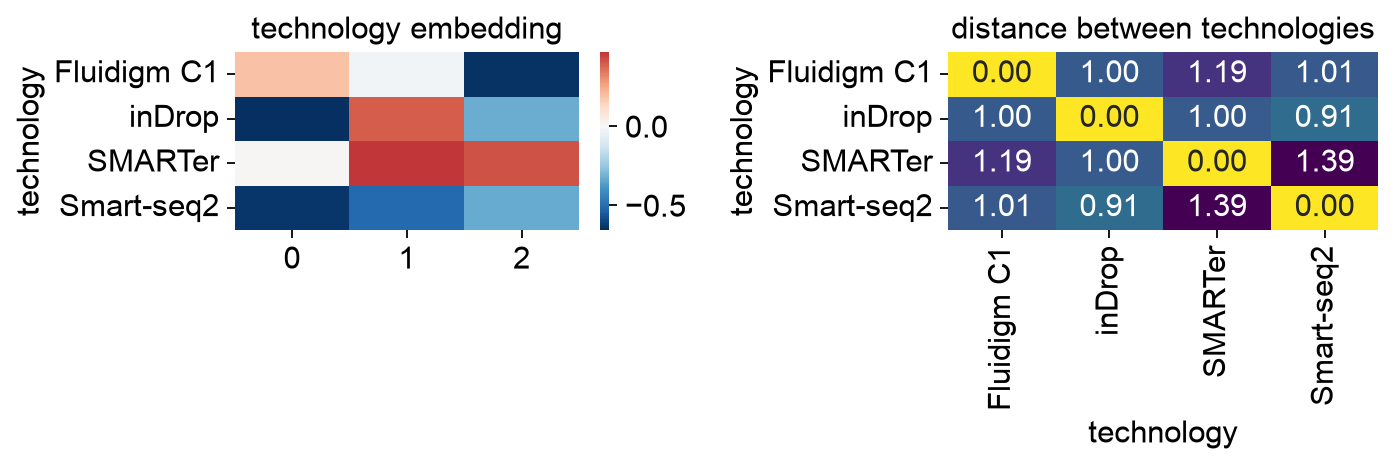

In [7]:
emb = model.get_conditional_embeddings()
tech = emb["technology"].to_df()
dist = pd.DataFrame(np.linalg.norm(tech.values[:, None] - tech.values[None], axis=-1),
                    index=tech.index, columns=tech.index)
with plt.rc_context({"axes.grid": False}):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    sns.heatmap(tech, cmap="RdBu_r", center=0, ax=axes[0])
    axes[0].set_title("technology embedding")
    sns.heatmap(dist, cmap="viridis_r", annot=True, fmt=".2f", ax=axes[1], cbar=False)
    axes[1].set_title("distance between technologies")
    plt.tight_layout()

## Query mapping

The query adds new studies and a new technology (CEL-Seq), so both keys gain embeddings.
`return_new_conditions=True` reports what was added.

In [8]:
query_model, new_conditions = SCPOLI.load_query_data(
    query, reference_model=model, labeled_indices=[], return_new_conditions=True
)
new_conditions

{'study': ['celseq', 'celseq2'], 'technology': ['CEL-Seq']}

In [9]:
query_model.train(n_epochs=50, pretraining_epochs=40, eta=10)

Epoch 50/50: 100%|██████████| 50/50 [00:24<00:00,  2.04it/s, v_num=1, train_loss=1.49e+3]


## Predictions at both levels

In [10]:
res = query_model.classify(query, scale_uncertainties=True, use_mean=True)
known = (query.obs.cell_type != "alpha").to_numpy()
for level in ["cell_type", "cell_type_coarse"]:
    query.obs[f"{level}_pred"] = res[level]["preds"]
    query.obs[f"{level}_uncert"] = res[level]["uncert"]
    acc = accuracy_score(query.obs[level][known], res[level]["preds"][known])
    print(f"{level:17s} accuracy on known types: {acc:.3f}")

cell_type         accuracy on known types: 0.971
cell_type_coarse  accuracy on known types: 0.995


Alpha cells have no fine-level prototype, so at the fine level they are assigned to other
types. At the coarse level, however, they are endocrine cells like beta, delta and gamma
cells, which the reference does have:

In [11]:
alpha = ~known
for level in ["cell_type", "cell_type_coarse"]:
    shares = query.obs.loc[alpha, f"{level}_pred"].value_counts(normalize=True)
    print(f"{level:17s} predictions of alpha cells:", shares[shares > 0.01].round(3).to_dict())

cell_type         predictions of alpha cells: {'gamma': 0.686, 'beta': 0.296}
cell_type_coarse  predictions of alpha cells: {'endocrine': 0.986}


## Finding and adding a new cell type

Unlabeled prototypes are cluster centres of the latent space, created on the query during
query training. We look for unlabeled prototypes whose nearest cells are mostly the
uncertain, unseen population. In practice, uncertainty and marker genes would guide this
step; here the held-out annotation lets us check the result.

In [12]:
info = query_model.get_prototypes_info("unlabeled")
z = query_model.get_latent(query, mean=True)
nearest = ((z[:, None, :] - info.X[None]) ** 2).sum(-1).argmin(1)
summary = pd.DataFrame({
    "cells": np.bincount(nearest, minlength=info.n_obs),
    "mean uncertainty": pd.Series(query.obs.cell_type_uncert.values).groupby(nearest).mean(),
    "share alpha": pd.Series(alpha).groupby(nearest).mean(),
}).fillna(0).round(3)
summary.sort_values("mean uncertainty", ascending=False).head(8)

,cells,mean uncertainty,share alpha
17,42,0.542,0.048
6,142,0.394,1.000
20,122,0.393,0.975
5,150,0.375,0.980
11,167,0.359,0.994
4,214,0.340,1.000
10,212,0.297,0.986
13,159,0.232,0.019


In [13]:
candidates = summary.index[(summary["share alpha"] > 0.8) & (summary["cells"] > 0)].tolist()
print("unlabeled prototypes forming the new type:", candidates)

query_model.add_new_cell_type("alpha", obs_key="cell_type", prototypes=candidates, adata=query)
res = query_model.classify(query, use_mean=True)["cell_type"]
query.obs["cell_type_pred_new"] = res["preds"]
print("alpha cells now predicted as alpha:", round(float((res["preds"][alpha] == "alpha").mean()), 3))
print("other cells predicted as alpha:   ", round(float((res["preds"][known] == "alpha").mean()), 3))

unlabeled prototypes forming the new type: [4, 5, 6, 10, 11, 20]
alpha cells now predicted as alpha: 0.974
other cells predicted as alpha:    0.004


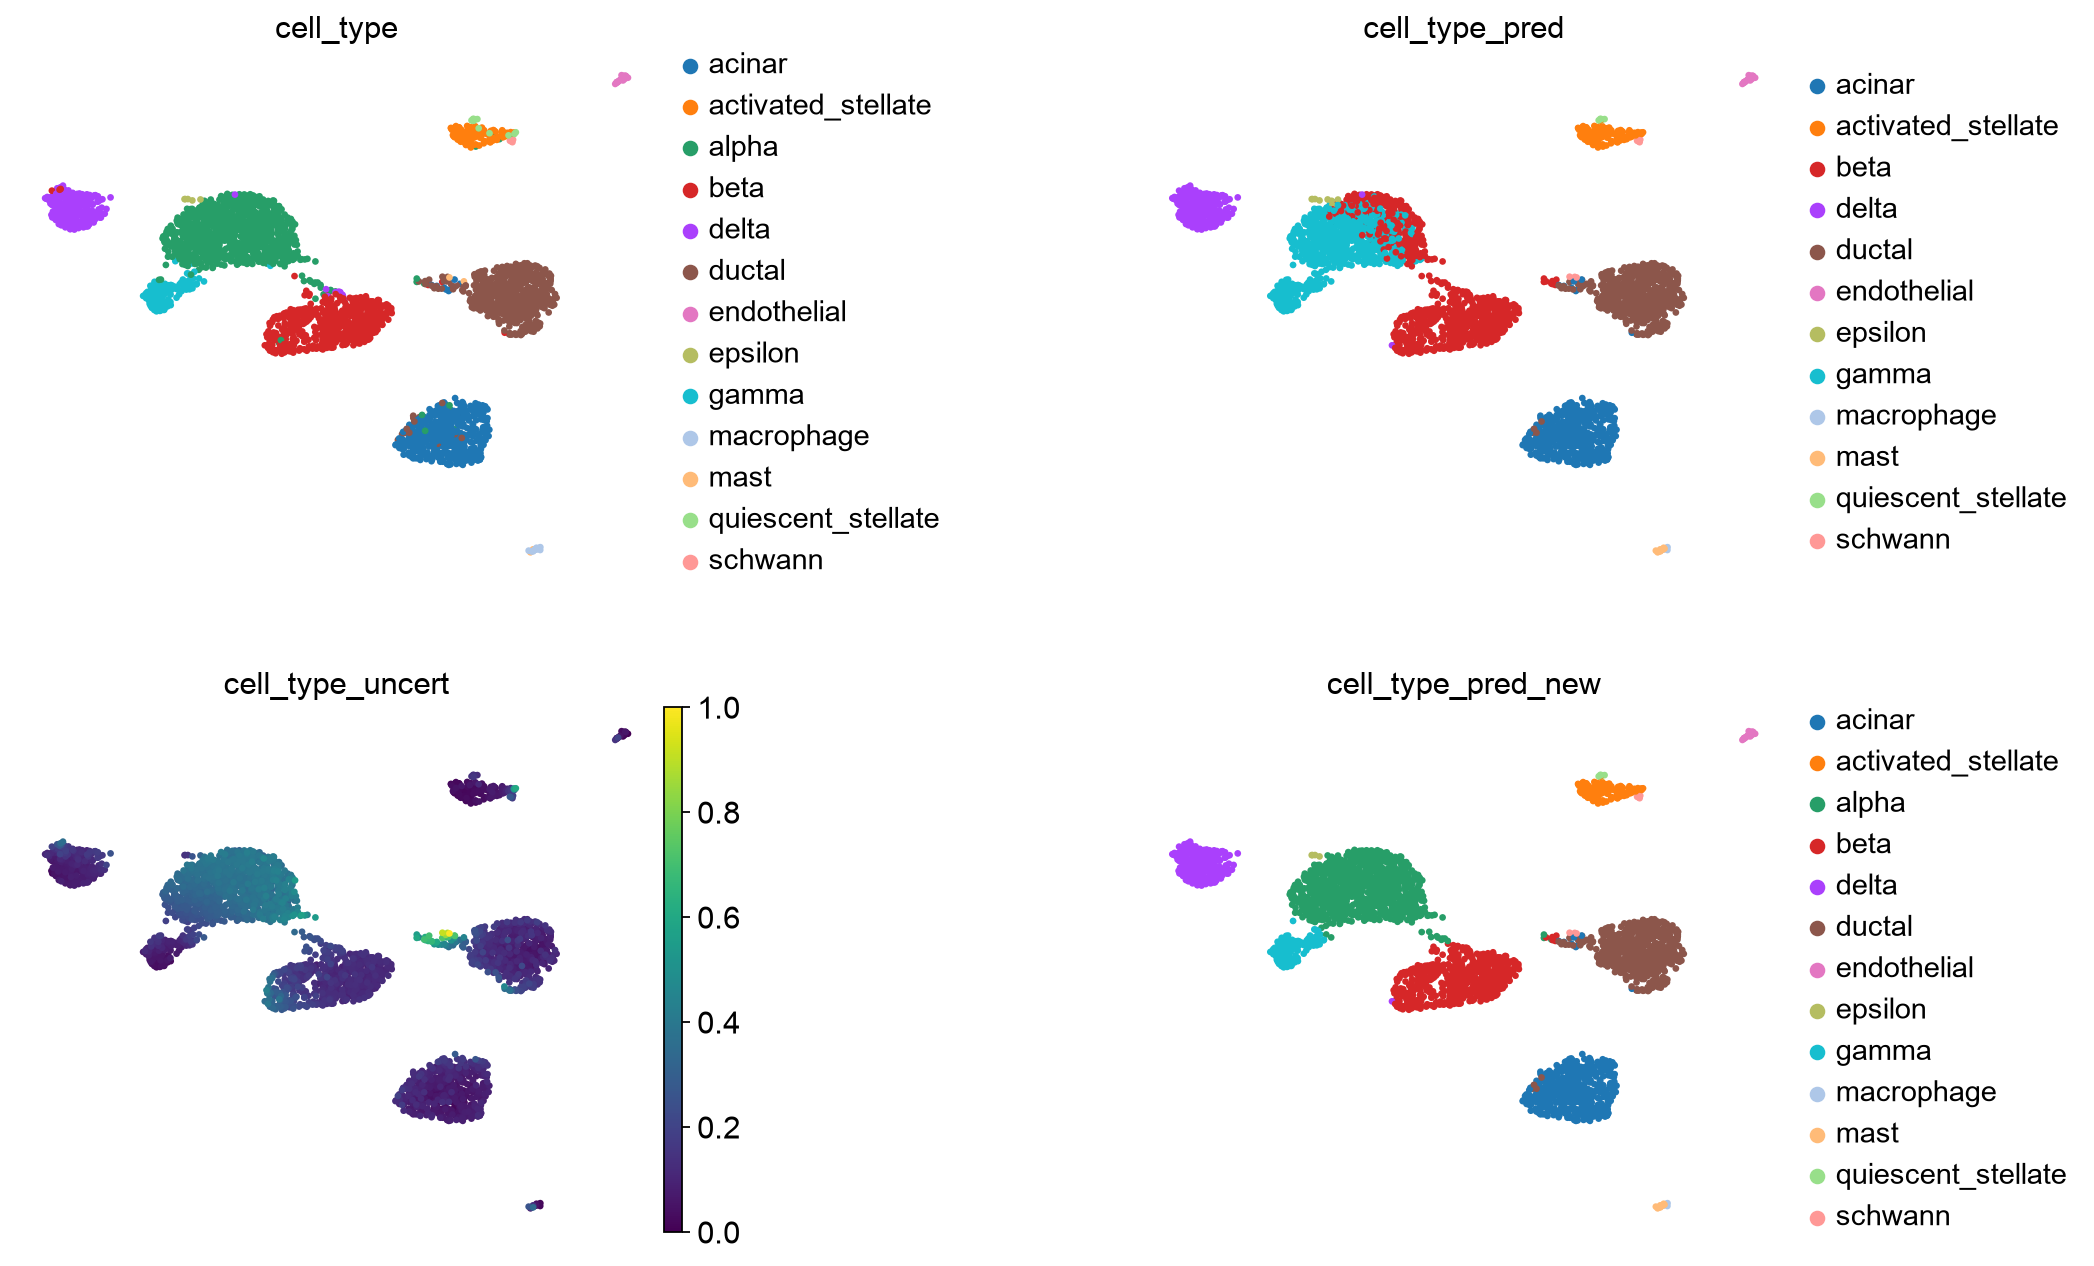

In [14]:
query.obsm["X_scpoli"] = z
sc.pp.neighbors(query, use_rep="X_scpoli")
sc.tl.umap(query)
# one colour per cell type across all panels
label_cols = ["cell_type", "cell_type_pred", "cell_type_pred_new"]
all_types = sorted(set().union(*[set(query.obs[c].astype(str)) for c in label_cols]))
colours = dict(zip(all_types, sc.pl.palettes.default_20))
for c in label_cols:
    present = sorted(set(query.obs[c].astype(str)))
    query.obs[c] = pd.Categorical(query.obs[c].astype(str), categories=present)
    query.uns[f"{c}_colors"] = [colours[t] for t in present]
sc.pl.umap(query, color=["cell_type", "cell_type_pred", "cell_type_uncert", "cell_type_pred_new"],
           ncols=2, wspace=0.6)